In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones y estimaciones optimista, más probable y pesimista (en semanas) se adjunta. Suponga que la duración de cada actividad sigue una distribución triangular de parámetros $(a, m, b)$.

In [4]:
pregunta_1 = "1. Dibuje el grafo PERT, construya la matriz de caminos y calcule la duración del proyecto con las duraciones medias.  "
pregunta_2 = "2. Genere 10000 réplicas de las duraciones de las actividades y, con la matriz de caminos, obtenga la duración del proyecto en cada una. Calcule su media, desviación típica y percentiles 5, 50 y 95.  "
pregunta_3 = "3. Calcule la probabilidad de terminar en 37 semanas o menos y la duración que puede comprometerse con un 90% de probabilidad. Compare con la aproximación normal por el camino crítico y explique las diferencias.  "
pregunta_4 = "4. Calcule el índice de criticidad de cada ruta y de cada actividad. ¿Qué actividad no crítica convendría vigilar?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el grafo PERT, construya la matriz de caminos y calcule la duración del proyecto con las duraciones medias.  

2. Genere 10000 réplicas de las duraciones de las actividades y, con la matriz de caminos, obtenga la duración del proyecto en cada una. Calcule su media, desviación típica y percentiles 5, 50 y 95.  

3. Calcule la probabilidad de terminar en 37 semanas o menos y la duración que puede comprometerse con un 90% de probabilidad. Compare con la aproximación normal por el camino crítico y explique las diferencias.  

4. Calcule el índice de criticidad de cada ruta y de cada actividad. ¿Qué actividad no crítica convendría vigilar?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, a, m, b 
    ('A'     , '---'      , 1, 3, 5 ),
    ('B'     , '---'      , 5, 7, 9 ),
    ('C'     , '---'      , 6, 8, 10),
    ('D'     , 'A,B,C'    , 4, 7, 10),
    ('E'     , 'D'        , 2, 5, 8 ),
    ('F'     , 'E'        , 6, 9, 9 ),
    ('G'     , 'F'        , 4, 7, 10),
    ('H'     , 'F'        , 4, 9, 11),
], columns=['activity', 'predecessor', 'a', 'm', 'b']).set_index('activity')
datos_enunciado

,predecessor,a,m,b
activity,,,,
A,---,1,3,5
B,---,5,7,9
C,---,6,8,10
D,"A,B,C",4,7,10
E,D,2,5,8
F,E,6,9,9
G,F,4,7,10
H,F,4,9,11


El proyecto corresponde a la puesta en marcha de una línea de envasado; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Especificación de la línea',
    'B': 'Adjudicación de los equipos',
    'C': 'Obra civil y bancadas',
    'D': 'Recepción de la llenadora',
    'E': 'Recepción de la etiquetadora',
    'F': 'Montaje mecánico',
    'G': 'Instalación neumática',
    'H': 'Cableado y armarios de control',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Especificación de la línea
B,Adjudicación de los equipos
C,Obra civil y bancadas
D,Recepción de la llenadora
E,Recepción de la etiquetadora
F,Montaje mecánico
G,Instalación neumática
H,Cableado y armarios de control


# Resolución

Para la distribución triangular la media es $(a + m + b)/3$ y la varianza $(a^2 + m^2 + b^2 - ab - am - bm)/18$.

In [7]:
datos_proyecto = datos_enunciado.copy()
datos_proyecto['duration'] = datos_proyecto.eval('(a + m + b) / 3').round().astype(int)
datos_proyecto['variance'] = datos_proyecto.eval('(a**2 + m**2 + b**2 - a*b - a*m - b*m) / 18')
datos_proyecto['standard_deviation'] = np.sqrt(datos_proyecto['variance'])
datos_proyecto

,predecessor,a,m,b,duration,variance,standard_deviation
activity,,,,,,,
A,---,1,3,5,3,0.666667,0.816497
B,---,5,7,9,7,0.666667,0.816497
C,---,6,8,10,8,0.666667,0.816497
D,"A,B,C",4,7,10,7,1.500000,1.224745
E,D,2,5,8,5,1.500000,1.224745
F,E,6,9,9,8,0.500000,0.707107
G,F,4,7,10,7,1.500000,1.224745
H,F,4,9,11,8,2.166667,1.471960


In [8]:
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. Dibuje el grafo PERT, construya la matriz de caminos y calcule la duración del proyecto con las duraciones medias.  

In [ ]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

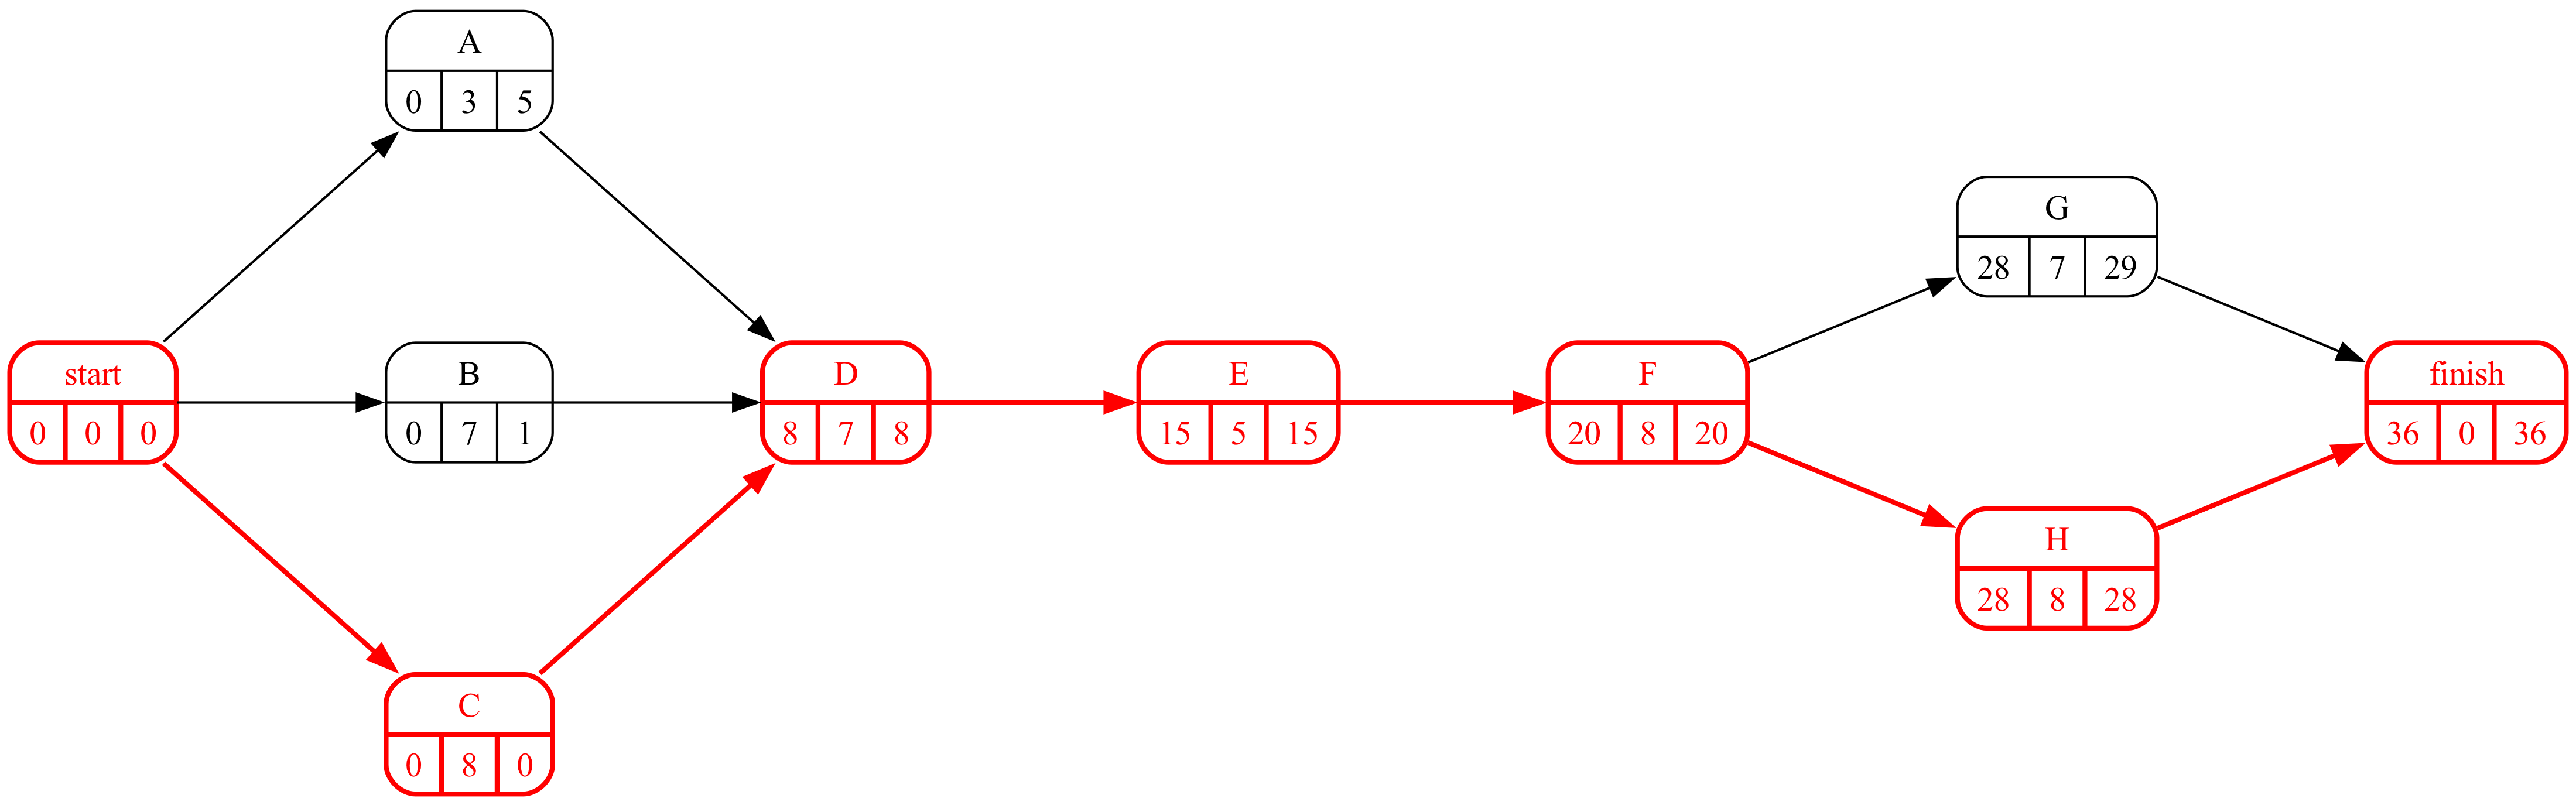

In [10]:
#| fig-cap: "Grafo Roy con las duraciones medias"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

In [11]:
#| tbl-cap: "Matriz de caminos"
#| label: tbl-matrizCaminos
path_matrix = proyecto.path_matrix(dummies=False)
proyecto.display_path_matrix(dummies=False)

,A,B,C,D,E,F,G,H
Route_1,1,0,0,1,1,1,1,0
Route_2,1,0,0,1,1,1,0,1
Route_3,0,1,0,1,1,1,1,0
Route_4,0,1,0,1,1,1,0,1
Route_5,0,0,1,1,1,1,1,0
Route_6,0,0,1,1,1,1,0,1


In [12]:
duraciones = datos_proyecto['duration'][path_matrix.columns]
duraciones_rutas_medias = path_matrix @ duraciones
duracion_media = int(duraciones_rutas_medias.max())
ruta_critica = duraciones_rutas_medias.idxmax()
desviacion_proyecto, varianza_rutas = proyecto.standard_deviation(durations=datos_proyecto['duration'], variances=datos_proyecto['variance'])
pd.concat([duraciones_rutas_medias.rename('duración media'),
           (path_matrix @ datos_proyecto['variance'][path_matrix.columns]).rename('varianza')], axis=1)

,duración media,varianza
Route_1,30,5.666667
Route_2,31,6.333333
Route_3,34,5.666667
Route_4,35,6.333333
Route_5,35,5.666667
Route_6,36,6.333333


In [13]:
Markdown(f'Con las duraciones medias el proyecto dura {duracion_media} semanas; la ruta crítica es {ruta_critica} y su desviación típica {desviacion_proyecto:.3f}.')

Con las duraciones medias el proyecto dura 36 semanas; la ruta crítica es Route_6 y su desviación típica 2.517.

## Apartado 2

In [14]:
display(Markdown(pregunta_2))

2. Genere 10000 réplicas de las duraciones de las actividades y, con la matriz de caminos, obtenga la duración del proyecto en cada una. Calcule su media, desviación típica y percentiles 5, 50 y 95.  

Cada réplica es un vector de duraciones generado con la distribución triangular de mínimo $a$, moda $m$ y máximo $b$ (cuando $a = m = b$ la duración es fija).

In [15]:
N = 10000
rng = np.random.default_rng(8006)
def muestras_triangular(a, m, b, size):
    return np.full(size, float(a)) if a == b else rng.triangular(a, m, b, size)
duraciones_mc = pd.DataFrame({act: muestras_triangular(fila['a'], fila['m'], fila['b'], N)
                              for act, fila in datos_proyecto.iterrows()})
duraciones_mc = duraciones_mc[path_matrix.columns]

In [16]:
#| tbl-cap: "Medias y desviaciones típicas muestrales frente a las teóricas"
#| label: tbl-comprobacionMuestras
pd.DataFrame({'media teórica': datos_proyecto['duration'], 'media muestral': duraciones_mc.mean(),
              'σ teórica': datos_proyecto['standard_deviation'], 'σ muestral': duraciones_mc.std()}).round(2).T

,A,B,C,D,E,F,G,H
media teórica,3.00,7.00,8.00,7.00,5.00,8.00,7.00,8.00
media muestral,2.99,7.00,8.01,6.98,5.00,7.99,7.00,7.98
σ teórica,0.82,0.82,0.82,1.22,1.22,0.71,1.22,1.47
σ muestral,0.82,0.81,0.82,1.22,1.23,0.71,1.23,1.47


La duración de cada ruta en cada réplica es el producto de las duraciones por la traspuesta de la matriz de caminos; la del proyecto, el máximo por filas.

In [17]:
duraciones_rutas_mc = duraciones_mc @ path_matrix.T
duracion_proyecto_mc = duraciones_rutas_mc.max(axis='columns')
pd.concat([duraciones_rutas_mc, duracion_proyecto_mc.rename('Proyecto')], axis=1).head().round(2)

,Route_1,Route_2,Route_3,Route_4,Route_5,Route_6,Proyecto
0,28.64,30.22,34.81,36.39,37.04,38.62,38.62
1,32.18,31.42,36.86,36.10,38.83,38.07,38.83
2,32.38,31.60,35.27,34.49,36.96,36.17,36.96
3,30.74,34.38,34.65,38.30,35.43,39.07,39.07
4,35.68,33.77,40.16,38.25,40.88,38.98,40.88


In [18]:
#| tbl-cap: "Descriptores de la duración simulada del proyecto"
#| label: tbl-descriptores
duracion_proyecto_mc.describe(percentiles=[0.05, 0.5, 0.95]).round(2).to_frame('Duración del proyecto').T

,count,mean,std,min,5%,50%,95%,max
Duración del proyecto,10000.0,36.47,2.3,28.28,32.67,36.5,40.23,45.59


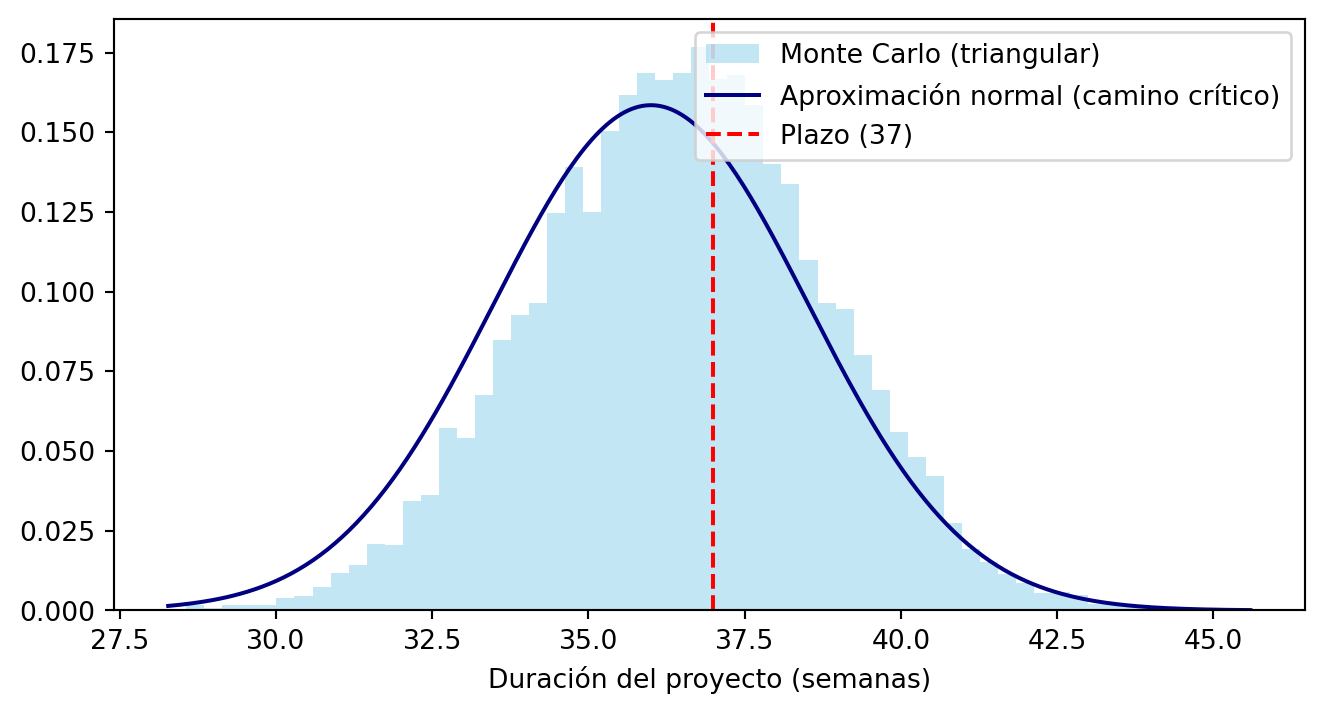

In [19]:
#| fig-cap: "Distribución simulada de la duración frente a la aproximación normal"
#| label: fig-histograma
from matplotlib import pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(duracion_proyecto_mc, bins=60, density=True, alpha=0.5, color='skyblue', label='Monte Carlo (triangular)')
x = np.linspace(duracion_proyecto_mc.min(), duracion_proyecto_mc.max(), 300)
ax.plot(x, norm.pdf(x, duracion_media, desviacion_proyecto), color='navy', label='Aproximación normal (camino crítico)')
ax.axvline(37, color='red', linestyle='--', label='Plazo (37)')
ax.set_xlabel('Duración del proyecto (semanas)'); ax.legend(); plt.show()

## Apartado 3

In [20]:
display(Markdown(pregunta_3))

3. Calcule la probabilidad de terminar en 37 semanas o menos y la duración que puede comprometerse con un 90% de probabilidad. Compare con la aproximación normal por el camino crítico y explique las diferencias.  

In [21]:
plazo, probabilidad_objetivo = 37, 0.9
p_mc = float((duracion_proyecto_mc <= plazo).mean())
t_mc = float(duracion_proyecto_mc.quantile(probabilidad_objetivo))
p_normal = float(norm.cdf((plazo - duracion_media) / desviacion_proyecto))
t_normal = float(duracion_media + norm.ppf(probabilidad_objetivo) * desviacion_proyecto)
pd.DataFrame({'Aproximación normal': [duracion_media, desviacion_proyecto, p_normal * 100, t_normal],
              'Monte Carlo': [duracion_proyecto_mc.mean(), duracion_proyecto_mc.std(), p_mc * 100, t_mc]},
             index=['Duración media', 'Desviación típica', f'P(T ≤ {plazo}) (%)', f'Duración para {int(probabilidad_objetivo*100)}%']).round(2)

,Aproximación normal,Monte Carlo
Duración media,36.00,36.47
Desviación típica,2.52,2.30
P(T ≤ 37) (%),65.44,58.76
Duración para 90%,39.23,39.42


La aproximación normal sólo mira la ruta crítica. En cada réplica, sin embargo, la duración del proyecto es el máximo de todas las rutas, y el máximo de varias variables aleatorias tiene una media mayor que cualquiera de ellas: las rutas casi críticas empujan la duración hacia arriba (*sesgo de fusión*). Por eso Monte Carlo da una duración media algo mayor y una probabilidad de cumplir el plazo algo menor: el método PERT clásico es optimista. La desviación típica simulada suele ser menor, porque cuando una ruta sale corta otra ocupa su lugar y la cola izquierda se recorta.

## Apartado 4

In [22]:
display(Markdown(pregunta_4))

4. Calcule el índice de criticidad de cada ruta y de cada actividad. ¿Qué actividad no crítica convendría vigilar?  

El índice de criticidad de una ruta es la fracción de réplicas en que es la más larga; el de una actividad, la fracción de réplicas en que pertenece a la ruta más larga.

In [23]:
#| tbl-cap: "Índice de criticidad de las rutas"
#| label: tbl-criticidadRutas
ruta_critica_mc = duraciones_rutas_mc.idxmax(axis='columns')
criticidad_rutas = (ruta_critica_mc.value_counts(normalize=True) * 100).reindex(path_matrix.index, fill_value=0.0)
actividades_ruta = path_matrix.apply(lambda fila: ' - '.join(fila.index[fila == 1]), axis=1)
pd.DataFrame({'actividades': actividades_ruta, 'duración media': duraciones_rutas_medias,
              'criticidad (%)': criticidad_rutas}).sort_values('criticidad (%)', ascending=False).round(1)

,actividades,duración media,criticidad (%)
Route_6,C - D - E - F - H,36,55.9
Route_5,C - D - E - F - G,35,24.1
Route_4,B - D - E - F - H,35,14.0
Route_3,B - D - E - F - G,34,6.0
Route_2,A - D - E - F - H,31,0.0
Route_1,A - D - E - F - G,30,0.0


In [24]:
#| tbl-cap: "Índice de criticidad de las actividades frente a su holgura total"
#| label: tbl-criticidadActividades
criticidad_actividades = path_matrix.loc[ruta_critica_mc].mean() * 100
calendario = proyecto.calendar(datos_proyecto['duration'])
pd.DataFrame({'holgura total': calendario['H_total'], 'criticidad (%)': criticidad_actividades}).round(1).T

,A,B,C,D,E,F,G,H
holgura total,5.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
criticidad (%),0.0,20.0,80.0,100.0,100.0,100.0,30.1,69.9


La librería hace el mismo cálculo de forma vectorizada: la sensibilidad empírica media de `monte_carlo` es precisamente el índice de criticidad de cada actividad.

In [25]:
resultado = proyecto.monte_carlo({act: ('triangular', fila['a'], fila['m'], fila['b']) for act, fila in datos_proyecto.iterrows()}, n_samples=N, seed=8006)
display(resultado.summary().round(2))
(resultado.sensitivity_mean * 100).round(1).to_frame('criticidad (%) según monte_carlo').T

,mean,std,q05,q50,q95,min,max
τ,36.47,2.3,32.67,36.5,40.23,28.28,45.59


,D,E,F,C,H,G,B,A
criticidad (%) según monte_carlo,100.0,100.0,100.0,80.0,69.9,30.1,20.0,0.0


In [26]:
vigilar = criticidad_actividades[calendario['H_total'] > 0].sort_values(ascending=False)
Markdown(f'''La actividad no crítica con mayor índice de criticidad es **{vigilar.index[0]}** ({vigilar.iloc[0]:.1f} % de las réplicas en la ruta más larga, con holgura {int(calendario.loc[vigilar.index[0], "H_total"])}). El análisis determinista la da por holgada, pero un retraso pequeño la convierte en crítica: es la que conviene vigilar.''')

La actividad no crítica con mayor índice de criticidad es **G** (30.1 % de las réplicas en la ruta más larga, con holgura 1). El análisis determinista la da por holgada, pero un retraso pequeño la convierte en crítica: es la que conviene vigilar.